# Batch calibration experiments

Use this notebook to inspect the archived per-setting data and reproduce individual comparisons. Run it from the repository root or the experiments directory. The [experiment guide](README.md) documents the baselines, data generation and complete solver reruns.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

here = Path.cwd()
exp = here / "experiments" if (here / "experiments" / "joint_stopping").is_dir() else here
results = exp / "extensions" / "results"
joint = exp / "joint_stopping"
assert (results / "planner_study.csv").is_file(), "Open the notebook from this checkout."

def plot(name):
    display(Image(filename=str(exp / "figures" / (name + ".png"))))


## Binary losses and the two comparisons

Counts against full enumeration measure the benefit of the complete procedure. The live timings compare joint stopping with independently stopped paths. Both use the same data and serial oracles.

In two-stage set covering, T is the number of independent demand realizations per calibration example. The loss compares first-stage cost plus mean recourse cost with the threshold.

The original exhaustive stage totals imply estimated speedups of 44.5× and 74.6× for T = 1 and T = 10. The paired independent-versus-joint wall-clock comparisons give 4.76× and 4.68×.

,family,realizations,cutoff,full_lp,independent_lp,joint_lp,full_losses,independent_losses,joint_losses
10,knapsack,1,0.498484,2498,1665,999,1273,803,420
18,set_cover,1,0.429481,23128,3702,961,11588,1780,368
34,set_cover,10,0.545421,23128,2526,750,11588,1197,257


method                  independent   joint  speedup
family    realizations                              
knapsack  1                   8.000   4.086    1.958
set_cover 1                  65.065  13.543    4.804
          10                176.919  40.119    4.410

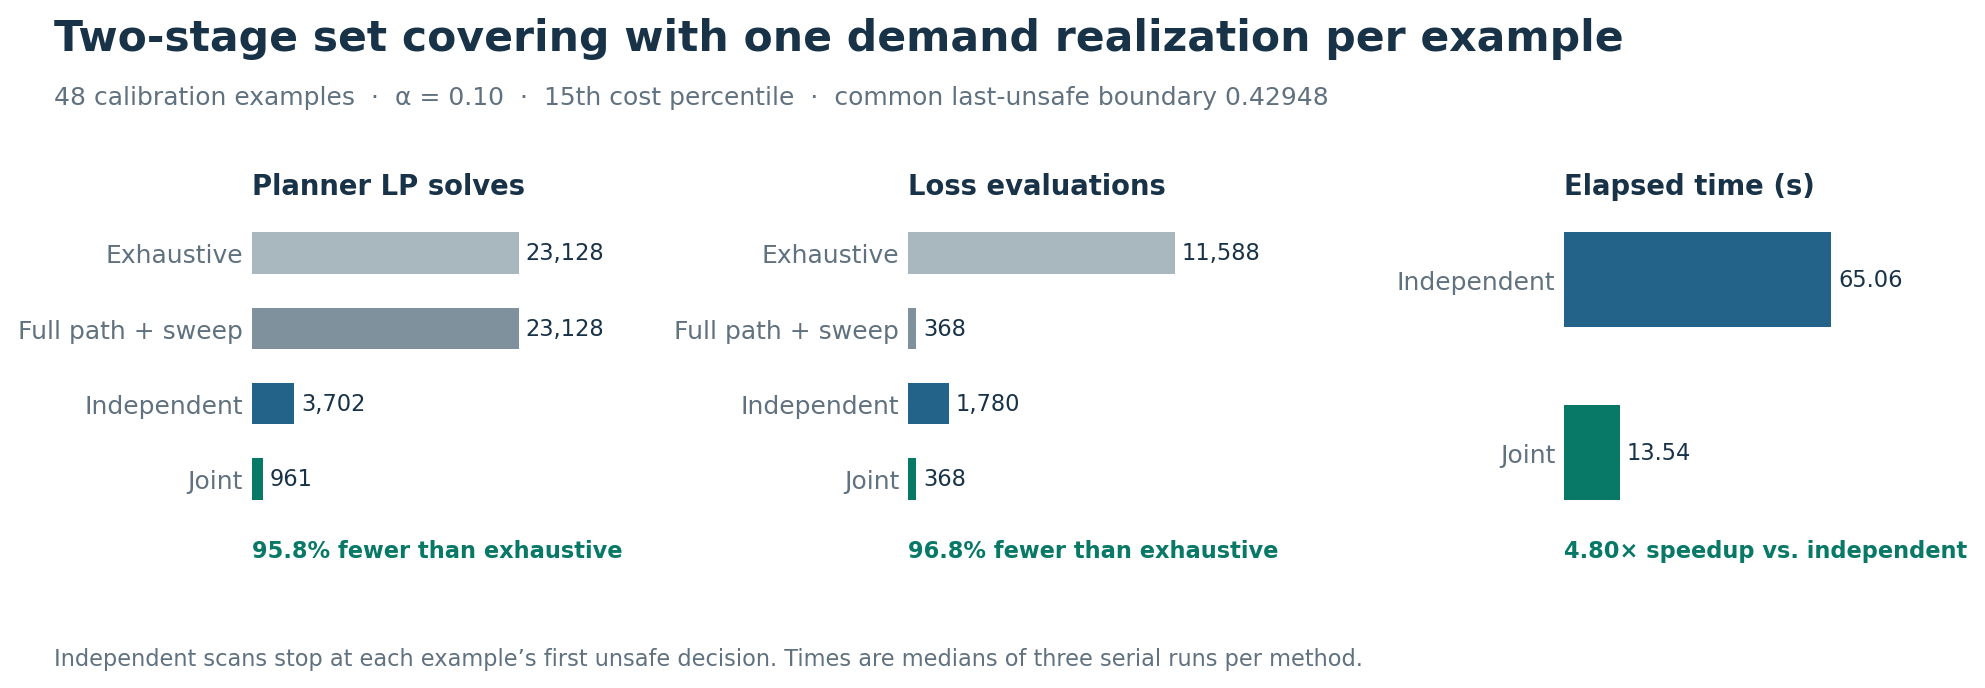

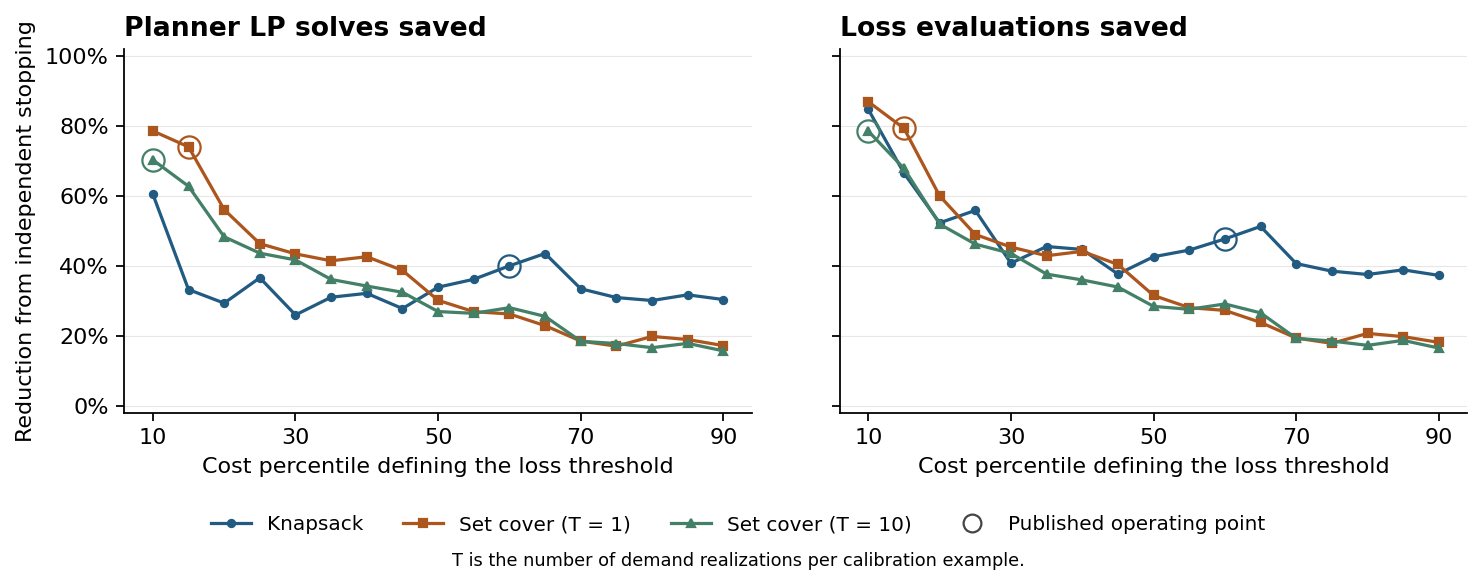

In [2]:
binary = pd.read_csv(joint / "thresholds.csv")
display(binary.loc[binary.chosen, ["family","realizations","cutoff","full_lp","independent_lp","joint_lp","full_losses","independent_losses","joint_losses"]])
times = pd.read_json(joint / "timings.jsonl", lines=True)
summary = times.pivot_table(index=["family","realizations"], columns="method", values="seconds", aggfunc="median")
summary["speedup"] = summary.independent / summary.joint
display(summary.round(3))
plot("set_cover_T1")
display(Image(filename=str(joint / "threshold_savings.png")))


## Graded loss on set-covering paths

The independent baseline can retire an example once its running maximum reaches one. The table reports its cost and the joint cost at the published binary operating thresholds. Inspect all 34 rows by displaying the entire dataframe.

,realizations,tau,boundary,nonmonotone,all_count,separate_count,joint_count,percent_saved
1,1,4.234867,0.132640,47,11588,11171,2347,78.990243
17,10,3.980090,0.162825,48,11588,10673,1755,83.556638


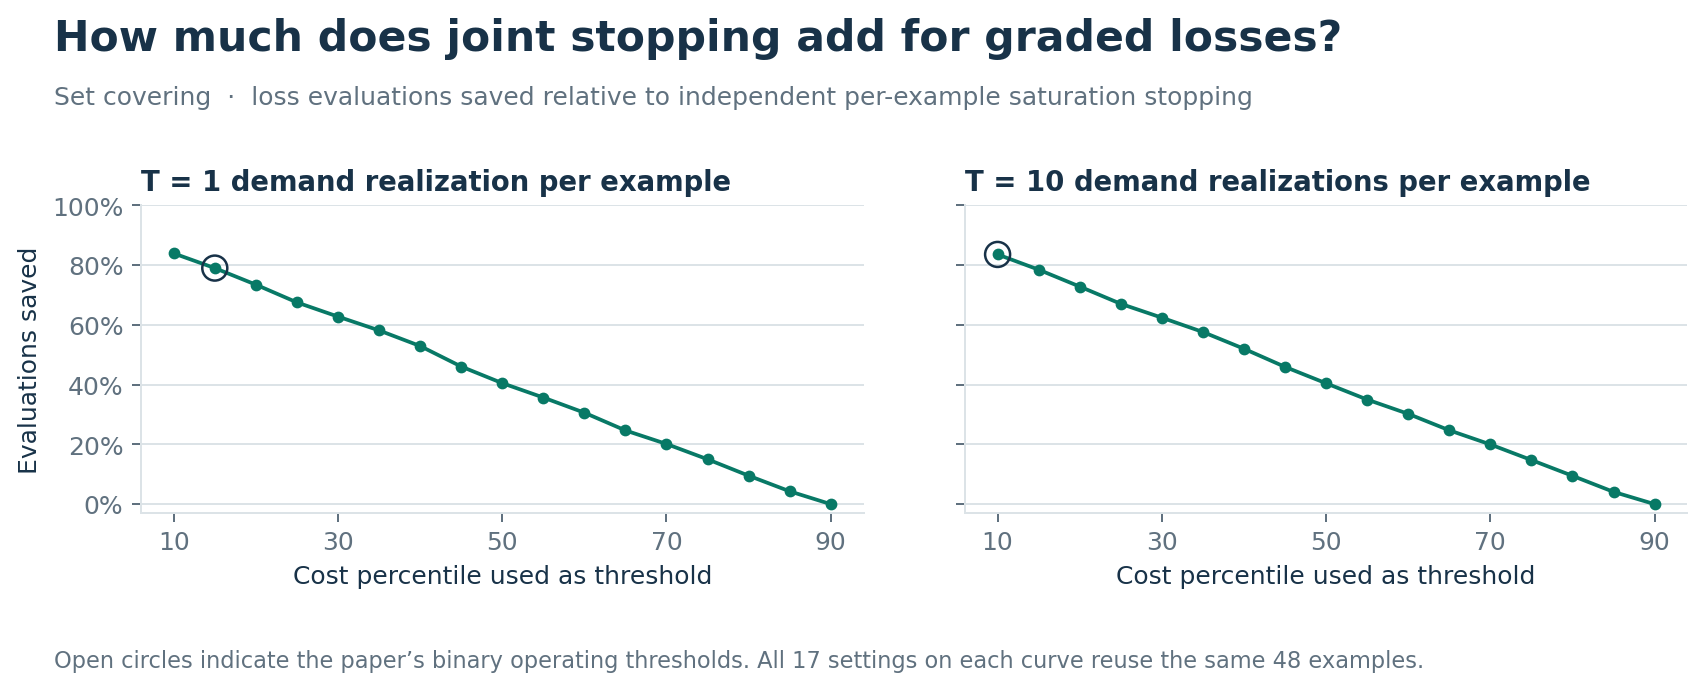

In [3]:
graded = pd.read_csv(results / "graded_counts.csv")
display(graded.loc[graded.paper_threshold, ["realizations","tau","boundary","nonmonotone","all_count","separate_count","joint_count","percent_saved"]])
plot("graded_thresholds")


## Grid selection across regimes

The tables average operation counts over 40 draws per setting. Both anchored and unanchored variants are included. Certified bisection is competitive when the last-unsafe indices are dense and broadly distributed.

,Full,CertBisect,AnchQS_3w,AnchQS_2w,UnanchQS_2w
Regime,,,,,
"Sparse Small-Cutoff (SDD-like, 35% unsafe)",13.0,4.89,2.74,2.13,2.06
Dense Small-Cutoff (90% unsafe),13.0,4.28,4.76,3.52,2.62
"Dense Uniform (High-Cutoff, 95% unsafe)",13.0,1.85,5.10,3.50,2.63


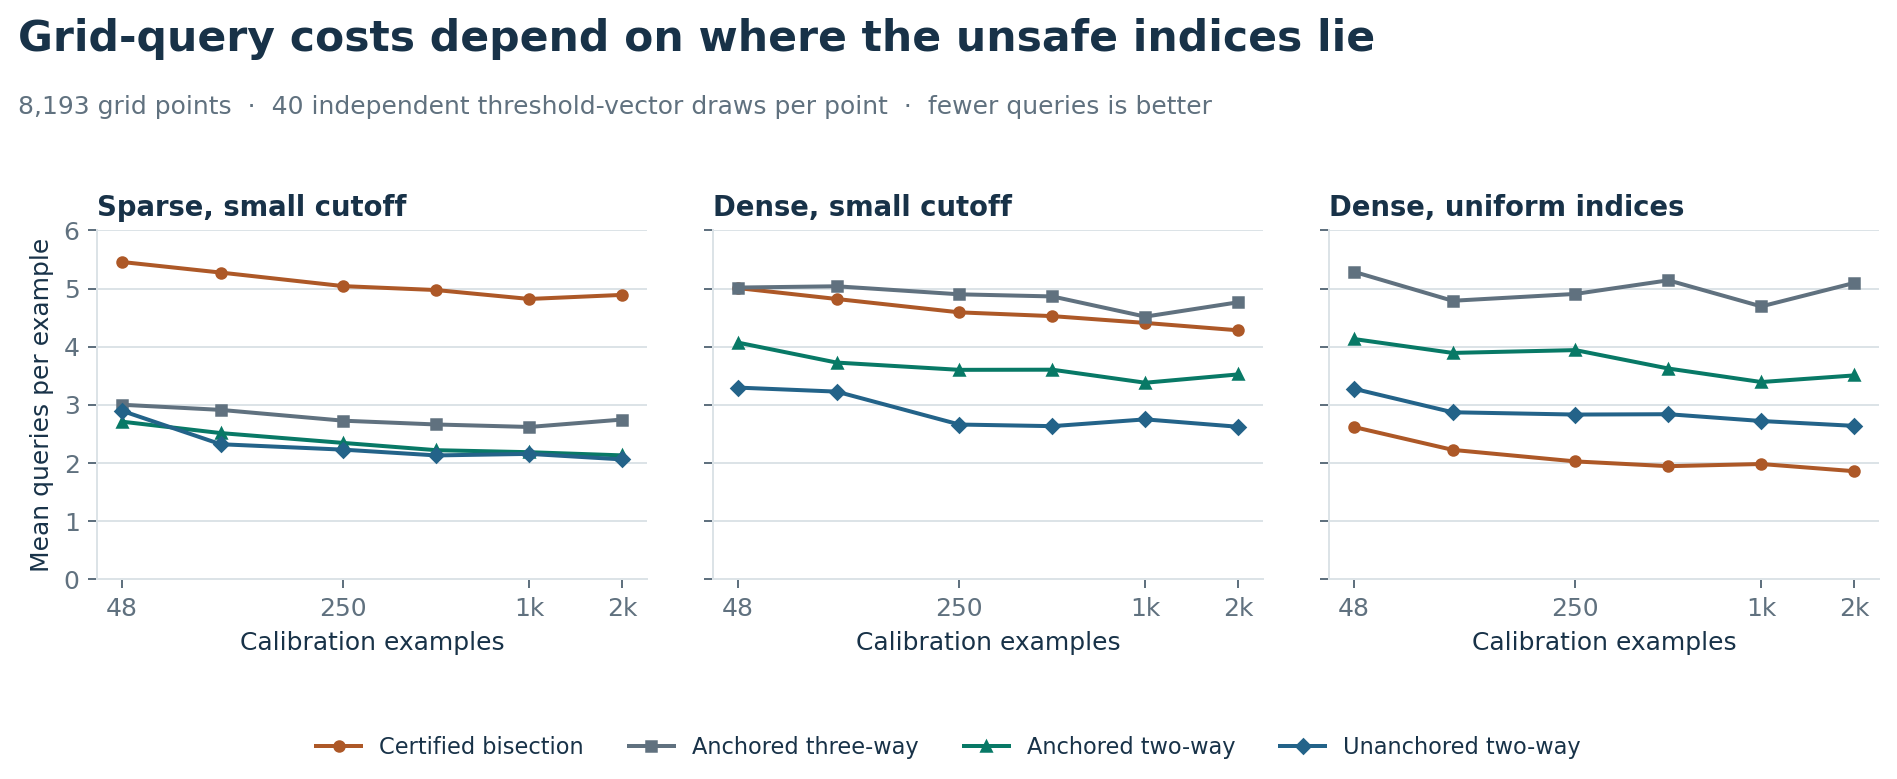

In [4]:
scale = pd.read_csv(results / "scaling.csv")
display(scale.query("J == 8193 and n == 2000").set_index("Regime")[["Full","CertBisect","AnchQS_3w","AnchQS_2w","UnanchQS_2w"]].div(2000).round(2))
plot("grid_scaling")


## Affine LP and binary-integer planners

Full enumeration and lazy generation are compared at the same continuous boundary. The grid comparison uses the suffix majorant on 129 grid points. Profit differences refer to the calibration scenes.

,planner,loss,boundary,grid_majorant_lambda,calibration_profit_gain_pct,full_solves,joint_solves,full_losses,joint_losses
0,lp,binary,0.239439,0.242188,2.174974,5101,2524,2601,1075
1,lp,continuous,0.219401,0.226562,3.677620,5101,2765,2601,1210
2,milp,binary,0.241079,0.242188,0.760975,2522,1931,1311,818
3,milp,continuous,0.222530,0.226562,1.329499,2522,2052,1311,894


,loss,exhaustive,solver
0,binary,0.241079,0.241079
1,continuous,0.222530,0.222530


,median_seconds,sign_optimum_feasible
parameter,,
0.05,0.007528,0
0.15,0.001954,0
0.30,0.001043,59
0.50,0.000952,60
0.70,0.000960,60
0.85,0.000984,60


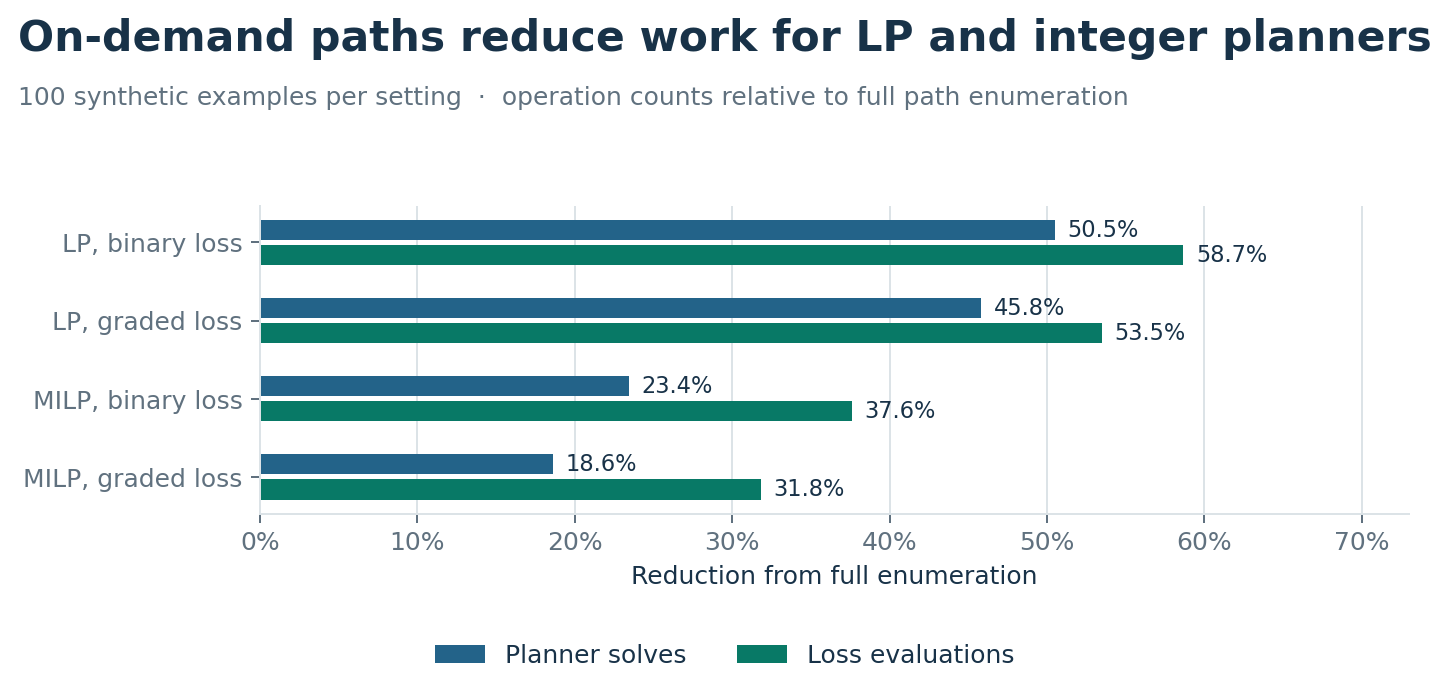

In [5]:
planners = pd.read_csv(results / "planner_study.csv")
display(planners[["planner","loss","boundary","grid_majorant_lambda","calibration_profit_gain_pct","full_solves","joint_solves","full_losses","joint_losses"]])
display(pd.read_csv(results / "exhaustive_milp_cutoffs.csv"))
latency = pd.read_csv(results / "milp_latency.csv")
display(latency.groupby("parameter").agg(median_seconds=("seconds","median"), sign_optimum_feasible=("sign_optimum_feasible","sum")))
plot("planner_savings")


## Held-out losses

500 splits per risk level reuse 300 scenes. The plot shows variability of held-out mean loss across those splits.

,heldout_loss,heldout_majorant
alpha,,
0.05,0.04364,0.04372
0.10,0.09511,0.09565
0.20,0.19474,0.19574


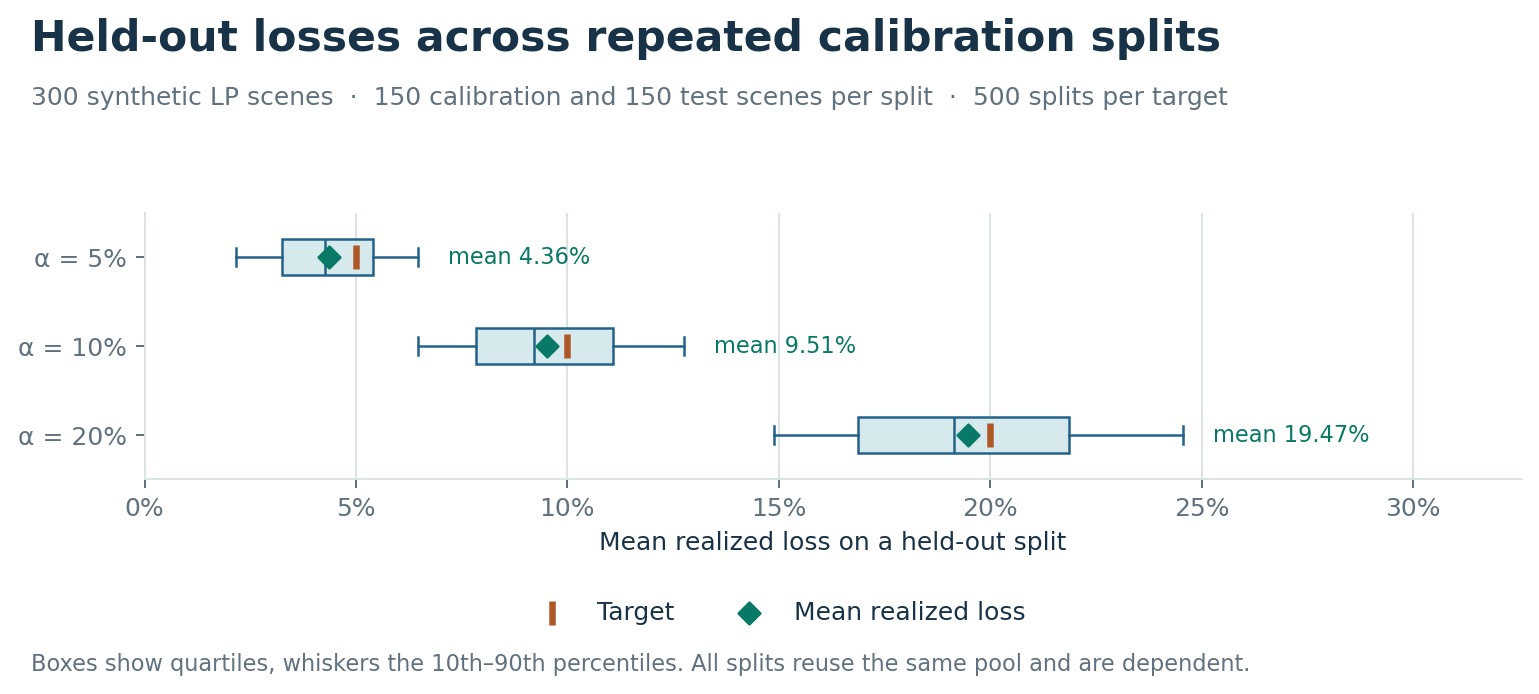

In [6]:
splits = pd.read_csv(results / "pool_splits.csv")
display(splits.groupby("alpha")[["heldout_loss","heldout_majorant"]].mean().round(5))
plot("heldout_risk")


## Reproduce the tables

From the root of this checkout, run `python experiments/verify.py` to replay the OR-Library results and edge cases. Run `python experiments/verify.py --full` to regenerate the synthetic studies and the exhaustive integer checks. Rebuilding the raw traces or taking fresh wall-clock measurements uses the commands in [the ablation guide](joint_stopping/README.md).